In [1]:
%load_ext autoreload
%autoreload 2

from curses import meta
import sys
import os
from pathlib import Path

# Dynamically set the working directory to the project root
project_root = Path.cwd().parent.parent
os.chdir(project_root)
sys.path.append(os.path.join(os.getcwd(), 'src'))

import ch
from ch.settings import load_settings
from ch.data_handling.metadata import load_metadata, create_metadata_summary

# Load settings
settings = load_settings()

# Load metadata - pass settings object
metadata = load_metadata(settings, 'subjects')
print(metadata.keys(), metadata.info())
print(metadata.head(10))
create_metadata_summary(settings, 'subjects')


20:01:46 - ch.data_handling.metadata - INFO - Loading subjects metadata from metadata/subject_metadata.parquet
20:01:46 - ch.data_handling.metadata - INFO - Loaded metadata for 594 subjects
20:01:46 - ch.data_handling.metadata - INFO - Loading subjects metadata from metadata/subject_metadata.parquet
20:01:46 - ch.data_handling.metadata - INFO - Loaded metadata for 594 subjects


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 594 entries, 0 to 593
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   subject_id      594 non-null    int64         
 1   age             594 non-null    uint8         
 2   dataset         594 non-null    object        
 3   scan_type       594 non-null    object        
 4   n_regions       594 non-null    int64         
 5   has_yeo_labels  594 non-null    bool          
 6   created_at      594 non-null    datetime64[us]
 7   updated_at      594 non-null    datetime64[us]
dtypes: bool(1), datetime64[us](2), int64(2), object(2), uint8(1)
memory usage: 29.1+ KB
Index(['subject_id', 'age', 'dataset', 'scan_type', 'n_regions',
       'has_yeo_labels', 'created_at', 'updated_at'],
      dtype='object') None
   subject_id  age dataset scan_type  n_regions  has_yeo_labels  \
0           1   24  camcan       DTI        376            True   
1      

{'total_subjects': 594,
 'datasets': {'camcan': 594},
 'age_stats': {'min': 18.0,
  'max': 88.0,
  'mean': 53.55723905723906,
  'std': 18.158685659402444},
 'scan_types': {'DTI': 594},
 'atlas_versions': {}}

In [2]:
from ch.data_handling import data_utils

data_utils.open_connectivity_dataset(settings)

<xarray.Dataset> Size: 672MB
Dimensions:       (subject_id: 594, node: 376, node_2: 376)
Coordinates:
  * subject_id    (subject_id) int32 2kB 1 2 3 4 5 6 ... 589 590 591 592 593 594
    age           (subject_id) int8 594B ...
  * node          (node) int32 2kB 0 1 2 3 4 5 6 ... 369 370 371 372 373 374 375
  * node_2        (node_2) int32 2kB 0 1 2 3 4 5 6 ... 370 371 372 373 374 375
Data variables:
    connectivity  (subject_id, node, node_2) float64 672MB ...
Attributes:
    atlas:        AAL-376
    description:  DTI structural connectivity (fiber density)
    layout:       subject,node,mode-compatible

In [3]:
# Compute connectome harmonics with option-encoded filename and self-describing attrs
from datetime import datetime
import xarray as xr
from ch.compute_harmonics.harmonics import compute_harmonics_dataset
from ch.data_handling.data_utils import open_connectivity_dataset

conn = open_connectivity_dataset(settings, atlas='AAL-376')
atlas = conn.attrs.get('atlas', 'unknown')
ages = metadata.set_index('subject_id')['age']

# Options
lap_type = 'normalized'
k = None
include_adjacency = False
symmetrize = True; zero_diagonal=True; clip_negative=True
binarize_threshold = None

harm = compute_harmonics_dataset(
    conn, lap_type=lap_type, k=k, include_adjacency=include_adjacency, ages=ages,
    symmetrize=symmetrize, zero_diagonal=zero_diagonal, clip_negative=clip_negative,
    binarize_threshold=binarize_threshold,
)
harm = harm.assign_attrs({
    'description': 'Connectome harmonics (graph Laplacian eigenpairs) from DTI connectivity',
    'atlas': atlas,
    'lap_type': lap_type,
    'k': -1 if k is None else int(k),
    'include_adjacency': bool(include_adjacency),
    'preprocess_symmetrize': bool(symmetrize),
    'preprocess_zero_diagonal': bool(zero_diagonal),
    'preprocess_clip_negative': bool(clip_negative),
    'created_at': datetime.utcnow().isoformat() + 'Z',
    'software': 'connectome-harmonics-code',
})

lap_slug = lap_type
k_slug = 'full' if k is None else f'k{k}'
pre_slug = []
if binarize_threshold is not None: pre_slug.append('bin')
if not include_adjacency: pre_slug.append('noA')
pre = ('_' + '-'.join(pre_slug)) if pre_slug else ''
harm_path = settings.processed_dir / f'harmonics_{atlas}_{lap_slug}_{k_slug}{pre}.nc'
harm.to_netcdf(harm_path, engine='scipy')
harm


<xarray.Dataset> Size: 1GB
Dimensions:     (subject_id: 594, node: 376, node_2: 376, mode: 376)
Coordinates:
  * subject_id  (subject_id) int64 5kB 1 2 3 4 5 6 7 ... 589 590 591 592 593 594
  * node        (node) int32 2kB 0 1 2 3 4 5 6 7 ... 369 370 371 372 373 374 375
  * node_2      (node_2) int32 2kB 0 1 2 3 4 5 6 ... 369 370 371 372 373 374 375
  * mode        (mode) int32 2kB 0 1 2 3 4 5 6 7 ... 369 370 371 372 373 374 375
    age         (subject_id) float64 5kB 24.0 28.0 28.0 23.0 ... 79.0 80.0 86.0
Data variables:
    adjacency   (subject_id, node, node_2) float64 672MB nan nan nan ... nan nan
    eigvecs     (subject_id, node, mode) float64 672MB -0.07861 ... 0.0002058
    eigvals     (subject_id, mode) float64 2MB 1.332e-15 0.05981 ... 1.524 1.631
Attributes:
    atlas:                     AAL-376
    layout:                    subject_id,node,mode
    description:               Connectome harmonics (graph Laplacian eigenpai...
    lap_type:                  normalized
    k:                         -1
    include_adjacency:         False
    preprocess_symmetrize:     True
    preprocess_zero_diagonal:  True
    preprocess_clip_negative:  True
    created_at:                2025-09-08T01:21:28.635405Z
    software:                  connectome-harmonics-code

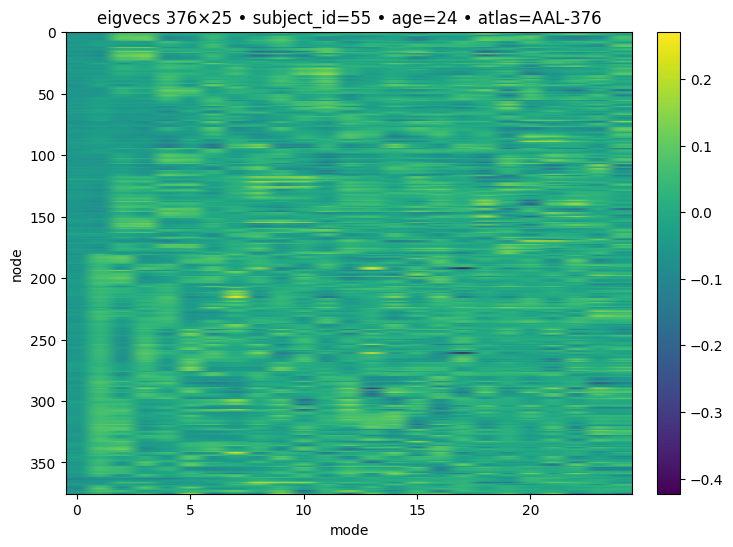

In [3]:
from re import S
from ch.data_handling.data_utils import open_harmonics_dataset
from ch.viz.heatmaps import plot_heatmap

harmonics_ds = open_harmonics_dataset(settings, path='data/processed/harmonics_AAL-376_normalized_full_noA.nc')

ax = plot_heatmap(settings, path='data/processed/harmonics_AAL-376_normalized_full_noA.nc', subject_id=55, n_harmonics=25)


In [8]:
harmonics_4 = harmonics_ds.sel(subject_id=4)

In [9]:
print(harmonics_4)

<xarray.Dataset> Size: 2MB
Dimensions:     (node: 376, node_2: 376, mode: 376)
Coordinates:
    subject_id  int32 4B 4
    age         float64 8B ...
  * node        (node) int32 2kB 0 1 2 3 4 5 6 7 ... 369 370 371 372 373 374 375
  * node_2      (node_2) int32 2kB 0 1 2 3 4 5 6 ... 369 370 371 372 373 374 375
  * mode        (mode) int32 2kB 0 1 2 3 4 5 6 7 ... 369 370 371 372 373 374 375
Data variables:
    adjacency   (node, node_2) float64 1MB ...
    eigvecs     (node, mode) float64 1MB ...
    eigvals     (mode) float64 3kB ...
Attributes:
    atlas:                     AAL-376
    layout:                    subject_id,node,mode
    description:               Connectome harmonics (graph Laplacian eigenpai...
    lap_type:                  normalized
    k:                         -1
    include_adjacency:         0
    preprocess_symmetrize:     1
    preprocess_zero_diagonal:  1
    preprocess_clip_negative:  1
    created_at:                2025-09-08T01:21:28.635405Z
    softw

In [13]:
V_da = harmonics_ds["eigvecs"].sel(subject_id=4).values

print(type(V_da))
print(V_da.shape)

<class 'numpy.ndarray'>
(376, 376)


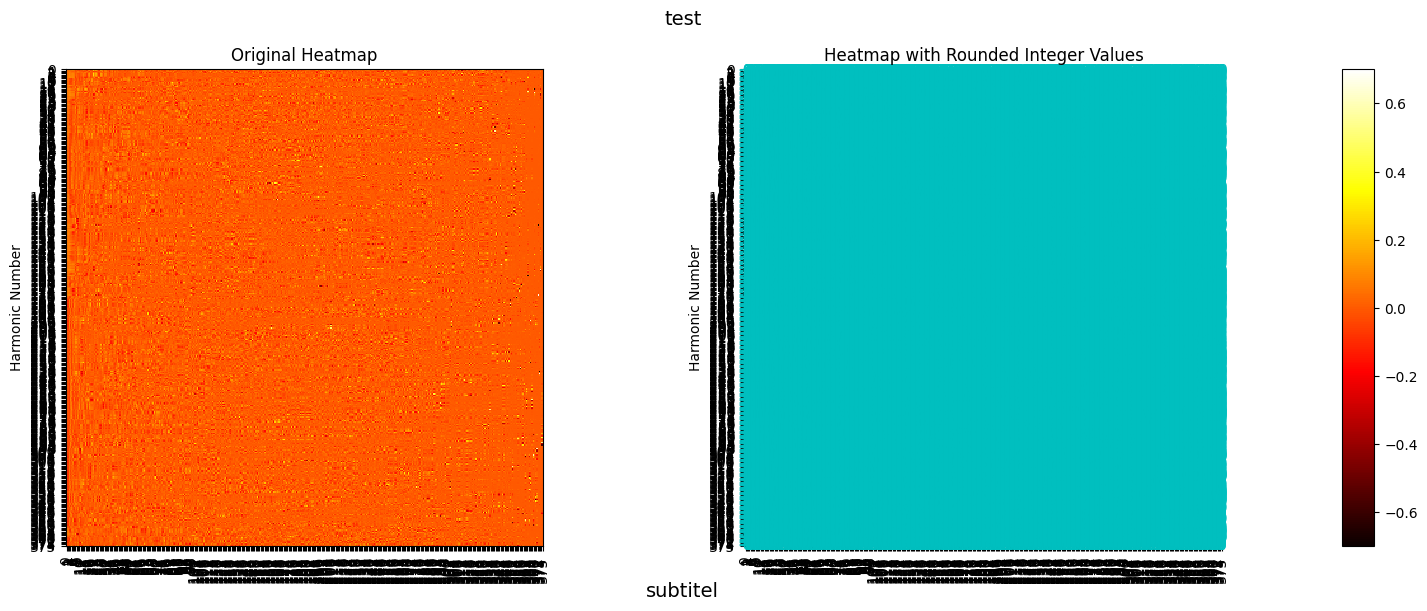

In [16]:
import matplotlib.pyplot as plt


def visualize_matrix(matrix, params):
    
    num_rows = params['num_harmonics'] 

    matrix = matrix[:num_rows, :num_rows]

    fig, axs = plt.subplots(1, 3, figsize=(15, 6), gridspec_kw={'width_ratios': [1, 1, 0.05]})

    # Original heatmap
    im = axs[0].imshow(matrix, cmap='hot', interpolation='nearest')
    axs[0].set_title('Original Heatmap')
    axs[0].set_ylabel('Harmonic Number')
    axs[0].set_xticks(range(num_rows))
    axs[0].set_yticks(range(num_rows))
    axs[0].set_xticklabels(range(num_rows), rotation=90)
    axs[0].set_yticklabels(range(num_rows))

    # Heatmap with rounded integer values
    im2 = axs[1].imshow(matrix, cmap='hot', interpolation='nearest')
    axs[1].set_title('Heatmap with Rounded Integer Values')
    axs[1].set_ylabel('Harmonic Number')
    axs[1].set_xticks(range(num_rows))
    axs[1].set_yticks(range(num_rows))
    axs[1].set_xticklabels(range(num_rows), rotation=90)
    axs[1].set_yticklabels(range(num_rows))

    # Annotate each cell with the rounded integer value
    for i in range(num_rows):
        for j in range(num_rows):
            axs[1].text(j, i, f'{matrix[i, j]:.0f}', ha='center', va='center', color='c')  # Cyan color for better visibility

    plt.suptitle(params['caption'], fontsize=14)
    plt.figtext(0.5, 0.01, params['subtitle'], fontsize=14, ha='center', va='center')

    # Position the colorbar to the right of the heatmaps
    fig.colorbar(im, cax=axs[2], orientation='vertical')

    plt.tight_layout()
    plt.show()


def interactive_heatmap(matrix, caption, subtitle, num_rows, show_in_IDE):
    
    filename = 'heatmap.html'

    # Reverse the order of rows for correct orientation
    matrix = np.flipud(matrix)

    # Create the heatmap
    fig = ff.create_annotated_heatmap(
        z=matrix,
        colorscale='hot',
        annotation_text=matrix.round().astype(int).astype(str),  
        showscale=True,
    )

    # Customize the layout
    fig.update_layout(
        autosize=False,
        width=350,
        height=350,
        margin=dict(
            l=50,
            r=50,
            b=100,
            t=100,
            pad=4
        ),
        title='Interactive Heatmap',
        xaxis_title='X Axis Title',
        yaxis_title='Y Axis Title',
        # Add this line to make the axes equal, thus making the heatmap square
        yaxis=dict(scaleanchor="x", scaleratio=1),
    )

    if show_in_IDE:
        # This will render the figure in a Jupyter Notebook
        fig.show()

    return fig


params = {
    'caption': 'test',
    'num_harmonics': 376,
    'subtitle': "subtitel"

}

visualize_matrix(V_da, params)